# Mini Project — Build a RAG System for Your Own Data
### IT7075: Applied AI for Cybersecurity · Retrieval-Augmented Generation

The first half of this notebook is the lecture pipeline with five pieces left for you to write, one per
step of the RAG recipe you saw in class:

| | Step | You write |
|---|---|---|
| **TODO 1** | chunk the documents | 3 lines |
| **TODO 2** | embed and store them in ChromaDB | 2 lines |
| **TODO 3** | retrieve the closest chunks | 3 lines |
| **TODO 4** | augment the prompt with what you retrieved | 2 lines |
| **TODO 5** | measure whether the answer was actually found | 4 lines |

Everything else is already written. Each TODO is marked like this, so you can find them by
searching for `###################`:

```
###################  TODO n — title  ###################
# what to do, and how
################
```

The five TODOs are practice on the course documents. After them, from Part 6 onward, no code is
provided: you build a RAG for data you create yourself, run your own experiments, and write it up in a
report and a video. Read `MiniProject_RAG.md` for the deliverables and the rubric.

> **Runs offline.** No API key needed. The generate step uses one if you have it, and otherwise
> prints an offline answer so the pipeline still works end to end.

## Part 1 — Chunk the documents  ·  **TODO 1**

The first few lines import what you need and load the embedding model — nothing to change there.
Then comes your first piece of code.

You cannot embed a whole document as one vector — one vector cannot represent ten topics. So you
cut each document into overlapping chunks, exactly as in Lecture 2. The **overlap** keeps a
sentence that lands on a boundary from being lost to both chunks.

> **Expected output:** `ssrf.txt -> 11 chunks`, `cybersecurity_kb.md -> 11 chunks`, **22 total**.

In [5]:
# If needed:  !pip install -q sentence-transformers chromadb pandas matplotlib openai
import json, os
import pandas as pd
import matplotlib.pyplot as plt

# Keep this notebook on the CPU. The model here is tiny (milliseconds either way),
# and this avoids the "CUDA error: no kernel image is available" failure -- or a very
# long hang while torch initialises -- on a machine whose PyTorch build does not match
# its GPU. This must run BEFORE anything imports torch.
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "")

from sentence_transformers import SentenceTransformer
import chromadb

# ---- the documents that came with the course -----------------------------
def kb_path(name):
    """The course files live in RAG/code/. Works from this folder or solutions/."""
    p = "../../code/" + name
    return p if os.path.exists(p) else "../../../code/" + name

COURSE_KB = [kb_path("ssrf.txt"), kb_path("cybersecurity_kb.md")]

# the question set for those documents (Part 5) sits next to this notebook
GOLDSET_FILE = ("baseline_goldset.json" if os.path.exists("baseline_goldset.json")
                else "../baseline_goldset.json")

# ---- ONE embedding model, used for BOTH the chunks and the questions -----
embedder = SentenceTransformer("all-MiniLM-L6-v2")     # 384 numbers per text, runs locally

def embed(texts):
    return embedder.encode(texts, normalize_embeddings=True).tolist()


###################  TODO 1 — cut a document into overlapping chunks  ###################
# WHAT: finish split_into_chunks() so it returns a list of text pieces.
#
# HOW (this is the Lecture 2 chunking cell):
#   * piece  = chunk_size characters of `text`, starting at `start`, with .strip()
#              applied so you don't keep leading/trailing whitespace
#   * append the piece to `pieces`, but ONLY if it is not an empty string
#   * move `start` forward by (chunk_size - overlap) -- NOT by chunk_size,
#     because the two chunks are supposed to share `overlap` characters
#
# WATCH OUT: if you move `start` forward by chunk_size you get no overlap at all;
#            if you forget to move it, the loop never ends.
################


def split_into_chunks(text, chunk_size=600, overlap=100):
    pieces = []
    start = 0
    while start < len(text):
        piece = text[start:start + chunk_size].strip()
        if piece:
            pieces.append(piece)
        start = start + chunk_size - overlap
    return pieces



# ---- given: apply it to both course documents ---------------------------
def load_and_chunk(files, chunk_size=600, overlap=100):
    """Read every file, chunk it, and remember which file each chunk came from."""
    chunks, sources = [], []
    for path in files:
        text = open(path, encoding="utf-8").read()
        pieces = split_into_chunks(text, chunk_size, overlap)
        chunks += pieces
        sources += [os.path.basename(path)] * len(pieces)
        print("  %-24s -> %2d chunks" % (os.path.basename(path), len(pieces)))
    return chunks, sources

chunks, sources = load_and_chunk(COURSE_KB)
print("  TOTAL:", len(chunks), "chunks")
print("\nFirst chunk starts:", chunks[0][:70])

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

  ssrf.txt                 -> 11 chunks
  cybersecurity_kb.md      -> 11 chunks
  TOTAL: 22 chunks

First chunk starts: Server-Side Request Forgery Prevention Cheat Sheet
Introduction
The ob


In [4]:

!git clone https://github.com/li2cc/IT7075-Applied-AI-for-Cybersecurity.git
%cd /content/IT7075-Applied-AI-for-Cybersecurity/04_RAG/assignments/project
!pwd


Cloning into 'IT7075-Applied-AI-for-Cybersecurity'...
remote: Enumerating objects: 232, done.
remote: Counting objects: 100% (232/232), done.
remote: Compressing objects: 100% (163/163), done.
remote: Total 232 (delta 70), reused 206 (delta 50), pack-reused 0 (from 0)
Receiving objects: 100% (232/232), 10.58 MiB | 25.50 MiB/s, done.
Resolving deltas: 100% (70/70), done.
/content/IT7075-Applied-AI-for-Cybersecurity/04_RAG/assignments/project
/content/IT7075-Applied-AI-for-Cybersecurity/04_RAG/assignments/project


In [2]:

%pip install -q chromadb sentence-transformers


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.0/52.0 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.3/23.3 MB 59.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 278.2/278.2 kB 16.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.5/7.5 MB 74.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 23.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.5/72.5 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.1/140.1 kB 6.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.3/60.3 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 206.3/206.3 kB 10.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.7/95.7 kB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.4/80.4 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.6/60.6 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 135.7/135

## Part 2 — Embed and store in ChromaDB  ·  **TODO 2**

Now turn every chunk into a vector and put it in the vector database, as in Lecture 2. The
collection is created for you with `cosine` distance — Chroma's default is a different metric, and
every threshold in this notebook assumes cosine.

> **Expected output:** `Stored 22 chunks`.

In [6]:
client = chromadb.EphemeralClient()
_counter = [0]

def build_collection(chunks, sources):
    """Given: make a NEW empty collection using cosine distance, then fill it."""
    _counter[0] += 1                     # a fresh name each time, so re-running
    name = "kb_%d" % _counter[0]         # never mixes old chunks with new ones
    collection = client.get_or_create_collection(name, metadata={"hnsw:space": "cosine"})

    ###################  TODO 2 — put the chunks in the database  ###################
    # WHAT: give collection.add() the two arguments it is still missing.
    #
    # HOW (the Lecture 2 "operate ChromaDB" cell):
    #   * embeddings = the vectors for `chunks`. Use the embed() helper from
    #     Part 1 -- the SAME model must embed the chunks and, later, the question,
    #     or the distances mean nothing.
    #   * metadatas  = one small dict per chunk recording where it came from:
    #                  [{"source": s} for s in sources]
    #                  This is what lets an answer cite a file.
    ################

    collection.add(ids=["c%d" % i for i in range(len(chunks))],
                   documents=chunks,
                   embeddings=embed(chunks),                       # <<< 1 line
                   metadatas=[{"source": s} for s in sources])
                             # <<< 1 line
    return collection


collection = build_collection(chunks, sources)
print("Stored", collection.count(), "chunks")

Stored 22 chunks


## Part 3 — Retrieve  ·  **TODO 3**

Embed the question with the same model, ask the database for the `k` closest chunks, and throw
away anything farther than `max_distance`.

That last step is the one people skip, and it matters: without it the database **always** returns
`k` chunks no matter how irrelevant, so your bot will happily answer a question your documents
never covered. An empty result is a *good* result — Part 4 turns it into "I don't know".

> **Expected output:** 4 hits for the SSRF question with distances around 0.36–0.43, and
> **0 hits** for "What is the capital of France?".

In [7]:
###################  TODO 3 — find the closest chunks  ###################
# WHAT: finish retrieve() so it returns a list of hits, closest first.
#       Each hit is a dict: {"text": ..., "distance": ..., "source": ...}
#
# HOW (the Lecture 3 retrieve cell):
#   * query the collection with the EMBEDDED question and n_results=k:
#         results = collection.query(query_embeddings=embed([question]), n_results=k)
#   * Chroma wraps its answer in a list (one entry per question, and we asked one),
#     so the pieces you want are:
#         results["documents"][0]   results["distances"][0]   results["metadatas"][0]
#   * keep a hit only when its distance <= max_distance
#
# REMEMBER: cosine distance, so SMALL = similar. 0.0 is identical, 1.0 is unrelated.
################

def retrieve(collection, question, k=4, max_distance=0.75):
    results = collection.query(query_embeddings=embed([question]), n_results=k)

    hits = []
    for doc, dist, meta in zip(results["documents"][0],
                               results["distances"][0],
                               results["metadatas"][0]):
        if dist <= max_distance:
            hits.append({"text": doc, "distance": dist, "source": meta["source"]})
    return hits



# ---- given: try it on a question the documents answer, and one they don't
for q in ["Is SSRF limited to HTTP, or can other protocols be involved?",
          "What is the capital of France?"]:
    found = retrieve(collection, q)
    print("Q:", q)
    print("   hits:", len(found))
    for h in found:
        print("     distance %.3f  [%s]  %s..." % (h["distance"], h["source"],
                                                   h["text"][:60].replace("\n", " ")))
    print()

Q: Is SSRF limited to HTTP, or can other protocols be involved?
   hits: 4
     distance 0.356  [ssrf.txt]  ed, and if poorly handled, can perform specific injection at...
     distance 0.399  [ssrf.txt]  teract with the internal/external network or the machine its...
     distance 0.405  [ssrf.txt]  ed to perform an SSRF attack. Take a look at the XXE cheat s...
     distance 0.431  [ssrf.txt]  ill be based on the following information:  String containin...

Q: What is the capital of France?
   hits: 0



## Part 4 — Augment the prompt and generate  ·  **TODO 4**

Augmentation is just building a string: paste the retrieved chunks into the prompt and tell the
model to answer from them only. `generate()` and `ask()` are written for you.

> **Expected output:** the SSRF question comes back tagged `[RAG]`; the Log4Shell question comes
> back tagged `[LLM]` with no context — the honest refusal from Lecture 3.

In [8]:
SYSTEM = (
    "You are a cybersecurity assistant. Answer the question using ONLY the context below.\n"
    "Cite the source file for every claim, like [ssrf.txt]. If the answer is in the context, start "
    "your reply with [RAG]. If the context is empty or does not contain the answer, say you do not "
    "know and start with [LLM] -- do not answer from memory.\n\n# Context\n{context}"
)

###################  TODO 4 — build the context block  ###################
# WHAT: finish build_context() so it turns a list of hits into ONE string.
#
# Format each hit like this, so the answer can be traced back to a file:
#
#     [1] (source: ssrf.txt)
#     <the chunk text>
#
#     [2] (source: cybersecurity_kb.md)
#     <the chunk text>
#
# HOW:
#   * loop over hits with  enumerate(hits, start=1)  so the numbering starts at 1
#   * build each block as  "[%d] (source: %s)\n%s" % (i, h["source"], h["text"])
#   * join the blocks with a BLANK LINE between them:  "\n\n".join(blocks)
#
# IMPORTANT: return "" when hits is empty. That empty string is what triggers the
#            [LLM] refusal path below -- do not return "no results" text instead.
################

def build_context(hits):
    if not hits:
        return ""
    blocks = []
    for i, h in enumerate(hits, start=1):
        blocks.append("[%d] (source: %s)\n%s" % (i, h["source"], h["text"]))
    return "\n\n".join(blocks)



# ---- given: generate an answer, then the whole pipeline in one function --
_USE_API = [True]      # set to False after one failure, so we don't retry a dead key

def generate(system, user):
    """Uses an LLM if one is available; otherwise quotes the context so this runs offline.

    The API call is guarded: if your key is missing, expired, or out of credit, the
    notebook prints one short note and keeps going in offline mode. Retrieval,
    scoring, and the whole tuning experiment do not need an LLM at all.
    """
    if os.getenv("OPENAI_API_KEY") and _USE_API[0]:
        try:
            from openai import OpenAI
            r = OpenAI().chat.completions.create(
                model="gpt-4o-mini", temperature=0,
                messages=[{"role": "system", "content": system},
                          {"role": "user", "content": user}])
            return r.choices[0].message.content
        except Exception as e:
            _USE_API[0] = False
            print("   (LLM unavailable - %s. Switching to offline mode for the rest of the"
                  " notebook; nothing in this project needs an LLM.)" % type(e).__name__)

    context = system.split("# Context\n", 1)[-1]
    if context.strip() == "" or context.strip() == "(nothing found)":
        return "[LLM] I don't know -- the documents do not cover this. (offline mode)"
    return "[RAG] (offline mode) From the retrieved context:\n" + context[:300]


def ask(collection, question, k=4, max_distance=0.75, show=True):
    """The complete RAG pipeline: retrieve -> augment -> generate."""
    hits = retrieve(collection, question, k, max_distance)
    context = build_context(hits)
    system = SYSTEM.format(context=context if context else "(nothing found)")
    answer = generate(system, question)
    if show:
        print("Q:", question)
        print("   grounded?", "YES, %d chunk(s)" % len(hits) if hits else "NO, nothing retrieved")
        print("   answer:", answer[:300].replace("\n", "\n           "), "\n")
    return {"hits": hits, "answer": answer}


_ = ask(collection, "What are the two basic cases in which SSRF can happen?")
_ = ask(collection, "What CVSS score did Log4Shell receive?")     # not in the documents

Q: What are the two basic cases in which SSRF can happen?
   grounded? YES, 4 chunk(s)
   answer: [RAG] (offline mode) From the retrieved context:
           [1] (source: ssrf.txt)
           ed to perform an SSRF attack. Take a look at the XXE cheat sheet to learn how to prevent exposure to XXE.
           Cases
           Depending on the application’s functionality and requirements, there are two basic cases in which SSRF can happen:
           
            

Q: What CVSS score did Log4Shell receive?
   grounded? NO, nothing retrieved
   answer: [LLM] I don't know -- the documents do not cover this. (offline mode) 



## Part 5 — Measure it  ·  **TODO 5**

To say one setting is better than another you need a number. `baseline_goldset.json` has **8
questions** about the course documents: **6 the documents answer** (each with the exact `evidence`
wording that proves it) and **2 they do not**.

Two counts, and that is all:

- **found** — of the 6 answerable questions, how many retrieved a chunk containing the evidence?
- **refused** — of the 2 unanswerable ones, how many correctly retrieved *nothing*?

> **Expected output at the Lecture 3 settings (k=4, threshold 0.75): found 6/6, refused 2/2.**

In [9]:
GOLDSET = json.load(open(GOLDSET_FILE))["questions"]
print("Loaded", len(GOLDSET), "questions\n")

###################  TODO 5 — score one configuration  ###################
# WHAT: finish score() so it counts `found` and `refused`.
#
# For each question q in the gold set, retrieve() is already called for you.
# Then:
#   * if q["answerable"] is True:
#       - the question counts as FOUND when ANY retrieved hit contains ANY of the
#         phrases in q["evidence"]. Compare in lower case, because the documents
#         are not consistently capitalised:
#             phrase.lower() in hit["text"].lower()
#       - a small helper, found_evidence(hits, q["evidence"]), is started for you
#   * if q["answerable"] is False:
#       - it counts as REFUSED when len(hits) == 0 -- nothing was retrieved
#
# WHY only these two numbers: `found` tells you whether the right text reached the
# model, and `refused` tells you whether the bot keeps quiet when it should. A
# setting that improves one while wrecking the other is not an improvement.
################

def found_evidence(hits, evidence):
    for h in hits:
        for phrase in evidence:
            if phrase.lower() in h["text"].lower():
                return True
    return False


def score(collection, goldset, k=4, max_distance=0.75):
    found, refused = 0, 0
    for q in goldset:
        hits = retrieve(collection, q["question"], k, max_distance)
        if q["answerable"]:
            if found_evidence(hits, q["evidence"]):
                found += 1
        else:
            if len(hits) == 0:
                refused += 1
    return found, refused



n_answerable = sum(q["answerable"] for q in GOLDSET)
n_unanswerable = len(GOLDSET) - n_answerable

found, refused = score(collection, GOLDSET)
print("found   %d/%d answerable questions" % (found, n_answerable))
print("refused %d/%d unanswerable questions" % (refused, n_unanswerable))

Loaded 8 questions

found   6/6 answerable questions
refused 2/2 unanswerable questions


## Part 6: from here on, the code is yours

Everything above ran on the course documents, and it was practice: the same pipeline you saw in the
lectures, one piece at a time. The rest of this notebook is a RAG for your own data, and no code is
provided for it. Reuse anything you wrote in Parts 1 to 5, adapt code from the lecture notebooks, or
write something different. What matters is that it works on your data and that you can explain it.

Add cells below that do all of the following:

1. Load your documents from `my_kb/` and report how many documents and how many characters you have.
2. Load your questions from `goldset.json`, and check that every evidence phrase really appears in your
   documents exactly as written. If one does not, your own results will report a miss that is not real.
3. Chunk, embed, and store your documents.
4. Answer your questions and print the transcript, including at least one question your documents cannot
   answer, so that the refusal is visible.
5. Run your experiments. Change one setting at a time, such as chunk size, the number of chunks
   retrieved, or the distance threshold, score each configuration against your gold set, collect the
   results in a table, and save it as `results.csv`.
6. Draw at least one chart from your results and save it as a `.png`.

The cells below are empty on purpose. Add as many more as you need.

> When you are finished, run the whole notebook top to bottom and save it with the outputs showing,
> then commit it to your private GitHub repository along with `my_kb/`, `goldset.json`, `results.csv`,
> and your chart. See `MiniProject_RAG.md` section 7.1 for the folder structure.

In [ ]:
###################  YOUR DATA — load and check  ###################
# Load your documents from my_kb/ and your questions from goldset.json.
# Report the document count and total characters, and check that every
# evidence phrase appears in your documents word-for-word.
################

### Build your RAG and ask your questions

In [ ]:
###################  YOUR RAG — build and ask  ###################
# Chunk, embed, and store your documents, then answer your own questions.
# Print the transcript, including a question your documents cannot answer.
################

### Run your experiments and collect the results

In [ ]:
###################  YOUR EXPERIMENTS  ###################
# Change one setting at a time, score each configuration against your gold
# set, collect the rows into a table, and save it as results.csv.
################

### Chart your results

In [ ]:
###################  YOUR CHART  ###################
# Draw at least one chart from your results and save it as a .png.
################

In [10]:

import os

os.makedirs("rag_project/my_kb", exist_ok=True)

print("Data folder created!")


Data folder created!


In [11]:

from pathlib import Path

folder = Path("rag_project/my_kb")
folder.mkdir(parents=True, exist_ok=True)

password_doc = """
# Password Security

## Creating Strong Passwords
Employees should use long, unique passwords for every work account.
A strong password should contain at least 15 characters when possible.
Passphrases made from several unrelated words can be easier to remember
than short, complicated passwords.

## Password Reuse
Employees should never reuse their work passwords on personal websites.
If one website experiences a data breach, attackers may try stolen
credentials on other services. This is called credential stuffing.

## Password Managers
An approved password manager helps employees generate and store
unique passwords securely. Employees should protect their password
manager with a strong master password and multifactor authentication.

## Password Sharing
Employees should never share passwords through email, text messages,
or workplace chat. IT support personnel should not need employees
to disclose their passwords.

## Compromised Passwords
If an employee suspects that a password has been stolen, they should
immediately report the incident to the security team and change
the affected password using a trusted login page.

## Account Protection
Employees should lock their computers when leaving their desks,
avoid saving passwords on shared computers, and use multifactor
authentication whenever available.
"""

(folder / "password_security.md").write_text(
    password_doc.strip(), encoding="utf-8"
)

print("Password Security document created!")
print("Characters:", len(password_doc.strip()))


Password Security document created!
Characters: 1323


In [12]:

from pathlib import Path

folder = Path("rag_project/my_kb")

phishing_doc = """
# Phishing Awareness

## What Is Phishing?
Phishing is a cyberattack where criminals impersonate trusted
organizations or individuals to trick employees into revealing
sensitive information. Attackers may use emails, text messages,
phone calls, or fake websites.

## Common Warning Signs
Phishing messages often create a sense of urgency. They may claim
that an account will be suspended or that immediate payment is
required. Other warning signs include unexpected attachments,
suspicious links, unusual sender addresses, and requests for
passwords or financial information.

## Email Phishing
Employees should carefully inspect the sender's email address
before responding to unexpected messages. A message may display
a familiar company name while using a fraudulent email domain.
Employees should avoid opening attachments or clicking links
when they cannot verify the sender.

## Spear Phishing
Spear phishing targets specific individuals or departments.
Attackers may research an employee's role, coworkers, or
organization to create convincing messages. These attacks
may appear to come from supervisors or trusted vendors.

## Business Email Compromise
Business email compromise occurs when attackers impersonate
executives, employees, or business partners to request money
transfers or sensitive information. Employees should verify
unexpected financial requests through an independently
confirmed communication channel.

## Recognizing Fake Websites
Fake websites may imitate legitimate login pages to steal
usernames and passwords. Employees should check the website
address carefully and avoid entering credentials on pages
opened through suspicious messages.

## Reporting Suspicious Messages
Employees should report suspected phishing attempts to their
IT or security team using the organization's approved process.
They should not forward suspicious attachments to coworkers
or attempt to investigate malicious links themselves.

## If an Employee Clicks a Phishing Link
If an employee accidentally clicks a suspicious link or enters
credentials into a fraudulent website, they should immediately
notify the security team. Quick reporting can help the
organization investigate and reduce potential damage.

## Preventing Phishing Attacks
Organizations should provide regular security awareness training,
email filtering, multifactor authentication, and clear reporting
procedures. Employees should remain cautious even when a
message appears to come from someone they know.
"""

(folder / "phishing_awareness.md").write_text(
    phishing_doc.strip(), encoding="utf-8"
)

print("Phishing Awareness document created!")
print("Characters:", len(phishing_doc.strip()))


Phishing Awareness document created!
Characters: 2488


In [13]:

from pathlib import Path

folder = Path("rag_project/my_kb")

mfa_doc = """
# Multifactor Authentication (MFA)

## What Is Multifactor Authentication?
Multifactor authentication is a security method that requires
users to provide two or more different types of verification
before accessing an account. MFA provides additional protection
when an employee's password is stolen or compromised.

## Types of Authentication Factors
Authentication factors generally fall into three categories:
something you know, such as a password or PIN; something you
have, such as a security key or authentication device; and
something you are, such as a fingerprint or facial recognition.
Using two passwords does not count as multifactor authentication
because both belong to the same category.

## Why MFA Is Important
Passwords can be stolen through phishing, data breaches, or
malware. MFA makes unauthorized account access more difficult
because attackers must also satisfy another verification step.
However, MFA does not eliminate every security risk.

## Common MFA Methods
Employees may use authenticator applications, hardware security
keys, passkeys, or one-time verification codes. Some organizations
also use SMS verification codes, although these can be vulnerable
to SIM-swapping and other interception attacks.

## Phishing-Resistant Authentication
Security keys and properly configured passkeys can provide
phishing-resistant authentication. These methods use
cryptographic verification linked to legitimate websites,
reducing the risk of employees entering reusable codes into
fraudulent login pages.

## MFA Fatigue Attacks
An MFA fatigue attack occurs when an attacker repeatedly sends
authentication approval requests to a user's device, hoping the
user will eventually approve one. Employees should never
approve a login request they did not initiate.

## Responding to Suspicious MFA Requests
Employees who receive unexpected MFA prompts should deny the
request and report it to the security team. They should also
follow company procedures for checking their account activity
and securing potentially compromised credentials.

## Protecting Authentication Devices
Employees should keep authentication devices secure, enable
device screen locks, and report lost or stolen devices promptly.
Backup authentication methods should be configured according
to company policy and stored securely.

## MFA and Remote Work
Employees accessing company applications remotely should use
approved MFA methods. Public or shared computers should not
be treated as trusted devices simply because MFA is enabled.

## MFA Limitations
MFA is one layer of defense. Employees must still recognize
phishing attempts, protect devices, use unique passwords,
and report suspicious account activity. Attackers may attempt
session theft or social engineering even when MFA is enabled.
"""

(folder / "multifactor_authentication.md").write_text(
    mfa_doc.strip(), encoding="utf-8"
)

print("MFA document created!")
print("Characters:", len(mfa_doc.strip()))


MFA document created!
Characters: 2788


In [14]:

from pathlib import Path

folder = Path("rag_project/my_kb")

browsing_doc = """
# Safe Browsing and Internet Security

## Why Safe Browsing Matters
Employees use the internet to access company applications,
communicate with customers, and research information.
Unsafe browsing can expose company devices to malware,
phishing attacks, and unauthorized access.

## Recognizing Suspicious Websites
Employees should carefully inspect website addresses before
entering sensitive information. Attackers may create websites
with addresses that closely resemble legitimate company domains.
Misspelled domain names, unexpected redirects, and unusual
login requests can indicate a suspicious website.

## Understanding HTTPS
HTTPS encrypts information transmitted between a browser
and a website. Employees should look for HTTPS when entering
sensitive information. However, HTTPS does not guarantee that
a website is legitimate because malicious websites can also
use valid HTTPS certificates.

## Avoiding Malicious Downloads
Employees should download software only from trusted sources
approved by their organization. Unexpected browser pop-ups
offering security updates or free software may contain malware.
Employees should avoid installing browser extensions or
applications without authorization.

## Browser Updates
Web browsers should be updated regularly to address known
security vulnerabilities. Employees should enable automatic
updates when permitted by company policy and restart their
browsers when updates require it.

## Public Wi-Fi Risks
Public Wi-Fi networks may expose employees to additional
security risks, especially when networks are unsecured or
impersonate legitimate hotspots. Employees should follow
company policies regarding VPN usage and remote access.
Sensitive company information should only be accessed
through approved and secure connections.

## Browser Extensions
Browser extensions can request access to browsing activity,
website content, and other information. Employees should
install only approved extensions and remove unnecessary ones.
An extension with excessive permissions may create privacy
or security risks.

## Protecting Company Information
Employees should avoid entering confidential company data
into unapproved websites or online tools. Personal cloud
storage accounts should not be used to transfer sensitive
work documents without authorization.

## Responding to Browser Warnings
Employees should not ignore browser warnings about unsafe
websites or invalid certificates. If a website displays a
security warning, employees should stop and contact their
IT department before continuing.

## Safe Browsing Habits
Employees should verify website addresses, avoid suspicious
links, keep browsers updated, and use approved software.
They should report unexpected downloads, unusual redirects,
or suspected malicious websites to the security team.

## Shared Computers
Employees should avoid accessing confidential work accounts
from shared or public computers. If a shared computer must
be used under an approved procedure, employees should
follow organizational security requirements and sign out
completely after their session.
"""

(folder / "safe_browsing.md").write_text(
    browsing_doc.strip(), encoding="utf-8"
)

print("Safe Browsing document created!")
print("Characters:", len(browsing_doc.strip()))


Safe Browsing document created!
Characters: 3097


In [15]:

from pathlib import Path

folder = Path("rag_project/my_kb")

incident_doc = """
# Cybersecurity Incident Reporting

## What Is a Security Incident?
A cybersecurity incident is an event that threatens the
confidentiality, integrity, or availability of information
or computer systems. Examples include unauthorized account
access, malware infections, stolen devices, and accidental
disclosure of sensitive company information.

## Recognizing Security Incidents
Employees should watch for unusual account activity,
unexpected password changes, suspicious login notifications,
missing files, unusual system behavior, or unexpected
security alerts. These signs may indicate a possible
security incident that requires investigation.

## Reporting an Incident
Employees should report suspected cybersecurity incidents
to their organization's IT or security team as soon as
possible. They should use the company's approved reporting
channel, such as a help desk ticket, security hotline,
or designated incident reporting email address.

## Information to Include in a Report
A useful incident report should include the date and time
of the event, the affected device or account, a description
of what happened, and any suspicious messages or alerts.
Employees should explain what actions they took before
and after discovering the incident.

## Reporting a Lost or Stolen Device
Employees should immediately report missing company laptops,
phones, or other devices. The security team may need to
disable accounts, revoke access, or remotely protect
company information stored on the device.

## Suspected Malware Infection
Employees who suspect malware should stop interacting with
suspicious files or websites and contact IT immediately.
They should follow instructions from the security team
rather than attempting to remove the malware themselves.

## Accidental Data Disclosure
Employees may accidentally send confidential information
to the wrong recipient or upload documents to an
unauthorized location. These situations should be
reported promptly, even if the employee believes
the information has not been accessed.

## Preserving Evidence
Employees should avoid deleting suspicious emails,
system logs, or other potential evidence unless
directed by the security team. Preserving evidence
helps investigators understand what happened.

## Incident Response Process
A typical incident response process includes preparation,
detection and analysis, containment, eradication,
recovery, and post-incident review. Security personnel
coordinate these activities to reduce damage and
restore normal operations.

## Why Quick Reporting Matters
Early reporting allows security teams to investigate
suspicious activity before an incident becomes more
serious. Delayed reporting can allow attackers to
maintain unauthorized access or expose additional data.

## Employee Responsibilities
Employees should follow company security policies,
complete required awareness training, protect
sensitive information, and report suspicious activity.
They should cooperate with incident response teams
and provide accurate information during investigations.

## Learning From Incidents
Organizations should review security incidents to
identify weaknesses and improve defenses. Lessons
learned may lead to updated procedures, additional
employee training, or stronger technical controls.
"""

(folder / "incident_reporting.md").write_text(
    incident_doc.strip(), encoding="utf-8"
)

print("Incident Reporting document created!")
print("Characters:", len(incident_doc.strip()))


Incident Reporting document created!
Characters: 3290


In [20]:

from pathlib import Path

folder = Path("rag_project/my_kb")
total = 0

for file in sorted(folder.glob("*.md")):
    count = len(file.read_text(encoding="utf-8"))
    total += count
    print(f"{file.name}: {count} characters")

print(f"\nTOTAL: {total} characters")


incident_reporting.md: 3290 characters
multifactor_authentication.md: 2788 characters
password_security.md: 1323 characters
phishing_awareness.md: 2488 characters
safe_browsing.md: 3097 characters

TOTAL: 12986 characters


In [21]:

from pathlib import Path

folder = Path("rag_project/my_kb")

sources = """
# Knowledge Base Sources

Project Topic: Cybersecurity Best Practices for Employees

The following five documents were created specifically
for this RAG project with assistance from ChatGPT.
They summarize general cybersecurity best practices
and are not copied from a single external source.

1. password_security.md
   Original AI-assisted document covering password
   creation, password managers, and account security.

2. phishing_awareness.md
   Original AI-assisted document covering phishing
   warning signs, prevention, and reporting.

3. multifactor_authentication.md
   Original AI-assisted document explaining MFA
   methods, security benefits, and common threats.

4. safe_browsing.md
   Original AI-assisted document covering safe
   internet browsing and online security.

5. incident_reporting.md
   Original AI-assisted document explaining
   cybersecurity incident identification,
   reporting, and response.

All five documents were prepared for educational
use as a custom RAG knowledge base.
"""

(folder / "SOURCES.md").write_text(
    sources.strip(), encoding="utf-8"
)

print("SOURCES.md created successfully!")


SOURCES.md created successfully!


---

## What to write up

The tables and charts above are the evidence. The report and the video are where you explain them.
See `MiniProject_RAG.md` for the full requirements. In short:

- Explain the complete RAG system in your own words: chunking, embeddings, the vector store, retrieval,
  augmentation, and generation, and where each one appears in your notebook.
- Describe the data you created and the questions you wrote, and why you chose the question your
  documents cannot answer.
- Report what your experiments showed: which setting changed your numbers most, what you would use, and
  whether anything found more answers while refusing less.
- Pick one question your RAG got wrong, look at the chunk it retrieved instead, and explain the mistake.

Submit one PDF report with the link to your GitHub project folder and the link to your video on its first
page. The notebook, `my_kb/`, `goldset.json`, `results.csv`, and your chart live in the repository, which
is private, with your instructor and the TA added as collaborators. The notebook must be committed with
its outputs showing.

In [23]:

import json
from pathlib import Path

project = Path("rag_project")
folder = project / "my_kb"

questions = [
    {
        "question": "Why should employees avoid reusing work passwords?",
        "answerable": True,
        "evidence": ["attackers may try stolen"]
    },
    {
        "question": "What should employees do if they receive an unexpected financial request?",
        "answerable": True,
        "evidence": ["unexpected financial requests"]
    },
    {
        "question": "What is an MFA fatigue attack?",
        "answerable": True,
        "evidence": ["repeatedly sends"]
    },
    {
        "question": "Does HTTPS guarantee that a website is legitimate?",
        "answerable": True,
        "evidence": ["HTTPS does not guarantee"]
    },
    {
        "question": "What information should employees include in a cybersecurity incident report?",
        "answerable": True,
        "evidence": ["date and time"]
    },
    {
        "question": "What should employees do after receiving an unexpected MFA prompt?",
        "answerable": True,
        "evidence": ["deny the"]
    },
    {
        "question": "What is the capital of France?",
        "answerable": False,
        "evidence": []
    },
    {
        "question": "What exact dollar amount did the company lose in a ransomware attack in 2025?",
        "answerable": False,
        "evidence": []
    }
]

# Load the five knowledge-base documents.
documents = {
    p.name: p.read_text(encoding="utf-8")
    for p in folder.glob("*.md")
    if p.name != "SOURCES.md"
}

assert len(documents) == 5, (
    f"Expected 5 documents, found {len(documents)}"
)

# Verify evidence and adjust for line breaks.
for q in questions:
    if q["answerable"]:
        for phrase in q["evidence"]:
            matched = False

            for text in documents.values():
                normalized = " ".join(text.split()).lower()

                if phrase.lower() in normalized:
                    matched = True
                    break

            assert matched, f"Evidence not found: {phrase}"

# Save the eight questions.
(project / "goldset.json").write_text(
    json.dumps({"questions": questions}, indent=2),
    encoding="utf-8"
)

print("goldset.json created successfully!")
print("Total questions:", len(questions))
print("Answerable:", sum(q["answerable"] for q in questions))
print("Unanswerable:", sum(not q["answerable"] for q in questions))


goldset.json created successfully!
Total questions: 8
Answerable: 6
Unanswerable: 2


In [24]:

import json
from pathlib import Path

project = Path("rag_project")
folder = project / "my_kb"

# Load the five cybersecurity documents.
documents = []
sources = []

for file in sorted(folder.glob("*.md")):
    if file.name == "SOURCES.md":
        continue

    text = file.read_text(encoding="utf-8")
    documents.append(text)
    sources.append(file.name)

# Load the eight test questions.
goldset = json.loads(
    (project / "goldset.json").read_text(encoding="utf-8")
)["questions"]

print("Documents loaded:", len(documents))
print("Questions loaded:", len(goldset))
print("Document names:", sources)


Documents loaded: 5
Questions loaded: 8
Document names: ['incident_reporting.md', 'multifactor_authentication.md', 'password_security.md', 'phishing_awareness.md', 'safe_browsing.md']


In [25]:

# Check that the evidence exists in the documents.
all_text = " ".join(" ".join(doc.split()) for doc in documents).lower()

for q in goldset:
    if q["answerable"]:
        for phrase in q["evidence"]:
            assert phrase.lower() in all_text, (
                f"Missing evidence: {phrase}"
            )

print("All evidence phrases verified!")

# Split documents into overlapping chunks.
def make_chunks(text, chunk_size=600, overlap=100):
    chunks = []
    start = 0

    while start < len(text):
        end = min(start + chunk_size, len(text))
        chunk = text[start:end].strip()

        if chunk:
            chunks.append(chunk)

        start += chunk_size - overlap

    return chunks

my_chunks = []
my_sources = []

for doc, source in zip(documents, sources):
    pieces = make_chunks(doc)

    my_chunks.extend(pieces)
    my_sources.extend([source] * len(pieces))

    print(f"{source}: {len(pieces)} chunks")

print("\nTotal chunks:", len(my_chunks))


All evidence phrases verified!
incident_reporting.md: 7 chunks
multifactor_authentication.md: 6 chunks
password_security.md: 3 chunks
phishing_awareness.md: 5 chunks
safe_browsing.md: 7 chunks

Total chunks: 28


In [26]:

import chromadb
from sentence_transformers import SentenceTransformer

# Load the embedding model.
my_model = SentenceTransformer("all-MiniLM-L6-v2")

# Convert document chunks into embeddings.
my_embeddings = my_model.encode(
    my_chunks, show_progress_bar=True
).tolist()

# Create a ChromaDB database.
my_client = chromadb.Client()

my_collection = my_client.get_or_create_collection(
    name="employee_cybersecurity"
)

# Clear old entries if this cell is rerun.
existing = my_collection.get()["ids"]
if existing:
    my_collection.delete(ids=existing)

# Store chunks, embeddings, and sources.
my_collection.add(
    ids=[f"chunk_{i}" for i in range(len(my_chunks))],
    documents=my_chunks,
    embeddings=my_embeddings,
    metadatas=[
        {"source": source}
        for source in my_sources
    ]
)

print("Vector database created successfully!")
print("Stored chunks:", my_collection.count())


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Vector database created successfully!
Stored chunks: 28


In [27]:

# Search the vector database for relevant information.

def retrieve_documents(question, top_k=3):
    question_embedding = my_model.encode(
        [question]
    ).tolist()

    results = my_collection.query(
        query_embeddings=question_embedding,
        n_results=top_k,
        include=["documents", "metadatas", "distances"]
    )

    return results

# Test with a cybersecurity question.
test_question = "What is an MFA fatigue attack?"

results = retrieve_documents(test_question)

print("QUESTION:", test_question)

for i in range(len(results["documents"][0])):
    print(f"\n--- Result {i + 1} ---")
    print("Source:", results["metadatas"][0][i]["source"])
    print("Distance:", round(results["distances"][0][i], 3))
    print("Text:", results["documents"][0][i][:400])


QUESTION: What is an MFA fatigue attack?

--- Result 1 ---
Source: multifactor_authentication.md
Distance: 0.591
Text: to
fraudulent login pages.

## MFA Fatigue Attacks
An MFA fatigue attack occurs when an attacker repeatedly sends
authentication approval requests to a user's device, hoping the
user will eventually approve one. Employees should never
approve a login request they did not initiate.

## Responding to Suspicious MFA Requests
Employees who receive unexpected MFA prompts should deny the
request and rep

--- Result 2 ---
Source: multifactor_authentication.md
Distance: 0.926
Text: ly because MFA is enabled.

## MFA Limitations
MFA is one layer of defense. Employees must still recognize
phishing attempts, protect devices, use unique passwords,
and report suspicious account activity. Attackers may attempt
session theft or social engineering even when MFA is enabled.

--- Result 3 ---
Source: multifactor_authentication.md
Distance: 0.988
Text: # Multifactor Authentication (MFA)


In [28]:

import re

def rag_answer(question, top_k=3, cutoff=0.85):
    results = retrieve_documents(question, top_k=top_k)

    distances = results["distances"][0]
    chunks = results["documents"][0]
    metadata = results["metadatas"][0]

    # Refuse when no sufficiently relevant document is found.
    if not distances or distances[0] > cutoff:
        return "[RAG] I don't have enough information in my documents to answer that question."

    # Find the most relevant sentence in the retrieved text.
    best_chunk = chunks[0]
    sentences = re.split(r'(?<=[.!?])\s+', best_chunk)

    question_words = set(
        re.findall(r'\b\w+\b', question.lower())
    ) - {"what", "why", "how", "does", "the", "is", "a", "an"}

    best_sentence = max(
        sentences,
        key=lambda s: len(
            question_words.intersection(
                re.findall(r'\b\w+\b', s.lower())
            )
        )
    )

    source = metadata[0]["source"]

    return f"[RAG] {best_sentence.strip()}\nSource: {source}"

# Test an answerable question.
print(rag_answer("What is an MFA fatigue attack?"))

print("\n------------------------\n")

# Test a question outside our documents.
print(rag_answer("What is the capital of France?"))


[RAG] ## MFA Fatigue Attacks
An MFA fatigue attack occurs when an attacker repeatedly sends
authentication approval requests to a user's device, hoping the
user will eventually approve one.
Source: multifactor_authentication.md

------------------------

[RAG] I don't have enough information in my documents to answer that question.


In [34]:

# Test the RAG system using all 8 questions.

correct_refusals = 0
incorrect_refusals = 0
answered_questions = 0

for i, item in enumerate(goldset, start=1):
    question = item["question"]
    expected_answerable = item["answerable"]

    response = rag_answer(question)

    refused = "I don't have enough information" in response

    if expected_answerable:
        if refused:
            incorrect_refusals += 1
        else:
            answered_questions += 1
    else:
        if refused:
            correct_refusals += 1

    print(f"\nQUESTION {i}: {question}")
    print("Expected answerable:", expected_answerable)
    print("Response:", response)
    print("-" * 60)

print("\n===== TEST SUMMARY =====")
print("Answerable questions answered:", answered_questions, "/ 6")
print("Unanswerable questions refused:", correct_refusals, "/ 2")
print("Incorrect refusals:", incorrect_refusals)



QUESTION 1: Why should employees avoid reusing work passwords?
Expected answerable: True
Response: [RAG] # Password Security

## Creating Strong Passwords
Employees should use long, unique passwords for every work account.
Source: password_security.md
------------------------------------------------------------

QUESTION 2: What should employees do if they receive an unexpected financial request?
Expected answerable: True
Response: [RAG] I don't have enough information in my documents to answer that question.
------------------------------------------------------------

QUESTION 3: What is an MFA fatigue attack?
Expected answerable: True
Response: [RAG] ## MFA Fatigue Attacks
An MFA fatigue attack occurs when an attacker repeatedly sends
authentication approval requests to a user's device, hoping the
user will eventually approve one.
Source: multifactor_authentication.md
------------------------------------------------------------

QUESTION 4: Does HTTPS guarantee that a website is le

In [30]:

# Identify the incorrectly refused question.

for item in goldset:
    if item["answerable"]:
        question = item["question"]
        results = retrieve_documents(question)

        distance = results["distances"][0][0]
        response = rag_answer(question)

        if "I don't have enough information" in response:
            print("INCORRECT REFUSAL FOUND")
            print("Question:", question)
            print("Distance:", round(distance, 3))
            print("Source:", results["metadatas"][0][0]["source"])


INCORRECT REFUSAL FOUND
Question: What should employees do if they receive an unexpected financial request?
Distance: 1.166
Source: incident_reporting.md


In [31]:

question = "What should employees do if they receive an unexpected financial request?"

results = retrieve_documents(question)

print("Question:", question)
print("Distance:", round(results["distances"][0][0], 3))
print("Source:", results["metadatas"][0][0]["source"])
print("Retrieved text:", results["documents"][0][0])


Question: What should employees do if they receive an unexpected financial request?
Distance: 1.166
Source: incident_reporting.md
Retrieved text: ice.

## Suspected Malware Infection
Employees who suspect malware should stop interacting with
suspicious files or websites and contact IT immediately.
They should follow instructions from the security team
rather than attempting to remove the malware themselves.

## Accidental Data Disclosure
Employees may accidentally send confidential information
to the wrong recipient or upload documents to an
unauthorized location. These situations should be
reported promptly, even if the employee believes
the information has not been accessed.

## Preserving Evidence
Employees should avoid deleting susp


In [32]:

import re

def retrieve_documents(question, top_k=3):
    question_embedding = my_model.encode([question]).tolist()

    results = my_collection.query(
        query_embeddings=question_embedding,
        n_results=min(10, my_collection.count()),
        include=["documents", "metadatas", "distances"]
    )

    keywords = set(re.findall(r"\b\w+\b", question.lower()))
    keywords -= {
        "what", "should", "do", "if", "they", "an",
        "a", "the", "is", "are", "who", "how", "employees"
    }

    ranked = []

    for doc, meta, distance in zip(
        results["documents"][0],
        results["metadatas"][0],
        results["distances"][0]
    ):
        doc_words = set(re.findall(r"\b\w+\b", doc.lower()))
        overlap = len(keywords & doc_words)

        score = distance - (0.15 * overlap)
        ranked.append((score, doc, meta, distance))

    ranked.sort(key=lambda x: x[0])
    ranked = ranked[:top_k]

    return {
        "documents": [[item[1] for item in ranked]],
        "metadatas": [[item[2] for item in ranked]],
        "distances": [[item[3] for item in ranked]]
    }

question = "What should employees do if they receive an unexpected financial request?"

results = retrieve_documents(question)

print("Top source:", results["metadatas"][0][0]["source"])
print("Distance:", round(results["distances"][0][0], 3))
print("Retrieved text:", results["documents"][0][0])


Top source: phishing_awareness.md
Distance: 1.313
Retrieved text: e, coworkers, or
organization to create convincing messages. These attacks
may appear to come from supervisors or trusted vendors.

## Business Email Compromise
Business email compromise occurs when attackers impersonate
executives, employees, or business partners to request money
transfers or sensitive information. Employees should verify
unexpected financial requests through an independently
confirmed communication channel.

## Recognizing Fake Websites
Fake websites may imitate legitimate login pages to steal
usernames and passwords. Employees should check the website
address carefully and


In [33]:

# Check retrieval distances for all 8 questions.

for i, item in enumerate(goldset, start=1):
    question = item["question"]
    results = retrieve_documents(question)

    distance = results["distances"][0][0]
    source = results["metadatas"][0][0]["source"]

    print(f"\nQuestion {i}: {question}")
    print("Expected answerable:", item["answerable"])
    print("Top source:", source)
    print("Distance:", round(distance, 3))
    print("-" * 40)



Question 1: Why should employees avoid reusing work passwords?
Expected answerable: True
Top source: password_security.md
Distance: 0.539
----------------------------------------

Question 2: What should employees do if they receive an unexpected financial request?
Expected answerable: True
Top source: phishing_awareness.md
Distance: 1.313
----------------------------------------

Question 3: What is an MFA fatigue attack?
Expected answerable: True
Top source: multifactor_authentication.md
Distance: 0.591
----------------------------------------

Question 4: Does HTTPS guarantee that a website is legitimate?
Expected answerable: True
Top source: safe_browsing.md
Distance: 0.77
----------------------------------------

Question 5: What information should employees include in a cybersecurity incident report?
Expected answerable: True
Top source: incident_reporting.md
Distance: 0.864
----------------------------------------

Question 6: What should employees do after receiving an unexpec

In [35]:

# Test a new cutoff of 1.35.

correct_answers = 0
correct_refusals = 0
incorrect_refusals = 0
incorrect_answers = 0

for i, item in enumerate(goldset, start=1):
    question = item["question"]

    response = rag_answer(question, cutoff=1.35)

    refused = "I don't have enough information" in response

    if item["answerable"] and not refused:
        correct_answers += 1
    elif item["answerable"] and refused:
        incorrect_refusals += 1
    elif not item["answerable"] and refused:
        correct_refusals += 1
    else:
        incorrect_answers += 1

    print(f"\nQuestion {i}: {question}")
    print("Response:", response)
    print("-" * 50)

print("\n===== UPDATED TEST SUMMARY =====")
print("Answerable questions answered:", correct_answers, "/ 6")
print("Unanswerable questions refused:", correct_refusals, "/ 2")
print("Incorrect refusals:", incorrect_refusals)
print("Incorrect answers:", incorrect_answers)



Question 1: Why should employees avoid reusing work passwords?
Response: [RAG] # Password Security

## Creating Strong Passwords
Employees should use long, unique passwords for every work account.
Source: password_security.md
--------------------------------------------------

Question 2: What should employees do if they receive an unexpected financial request?
Response: [RAG] Employees should verify
unexpected financial requests through an independently
confirmed communication channel.
Source: phishing_awareness.md
--------------------------------------------------

Question 3: What is an MFA fatigue attack?
Response: [RAG] ## MFA Fatigue Attacks
An MFA fatigue attack occurs when an attacker repeatedly sends
authentication approval requests to a user's device, hoping the
user will eventually approve one.
Source: multifactor_authentication.md
--------------------------------------------------

Question 4: Does HTTPS guarantee that a website is legitimate?
Response: [RAG] However, HTTP

In [36]:

import pandas as pd

cutoffs = [0.75, 0.85, 1.0, 1.2, 1.35, 1.5]

experiment_results = []

for cutoff in cutoffs:
    answered = 0
    correct_refusals = 0
    incorrect_refusals = 0
    incorrect_answers = 0

    for item in goldset:
        response = rag_answer(
            item["question"],
            cutoff=cutoff
        )

        refused = "I don't have enough information" in response

        if item["answerable"]:
            if refused:
                incorrect_refusals += 1
            else:
                answered += 1
        else:
            if refused:
                correct_refusals += 1
            else:
                incorrect_answers += 1

    experiment_results.append({
        "Cutoff": cutoff,
        "Answerable Answered": answered,
        "Correct Refusals": correct_refusals,
        "Incorrect Refusals": incorrect_refusals,
        "Incorrect Answers": incorrect_answers,
        "Total Correct Decisions": answered + correct_refusals
    })

df = pd.DataFrame(experiment_results)

print("EXPERIMENT RESULTS")
print(df.to_string(index=False))


EXPERIMENT RESULTS
 Cutoff  Answerable Answered  Correct Refusals  Incorrect Refusals  Incorrect Answers  Total Correct Decisions
   0.75                    2                 2                   4                  0                        4
   0.85                    4                 2                   2                  0                        6
   1.00                    5                 2                   1                  0                        7
   1.20                    5                 2                   1                  0                        7
   1.35                    6                 2                   0                  0                        8
   1.50                    6                 1                   0                  1                        7


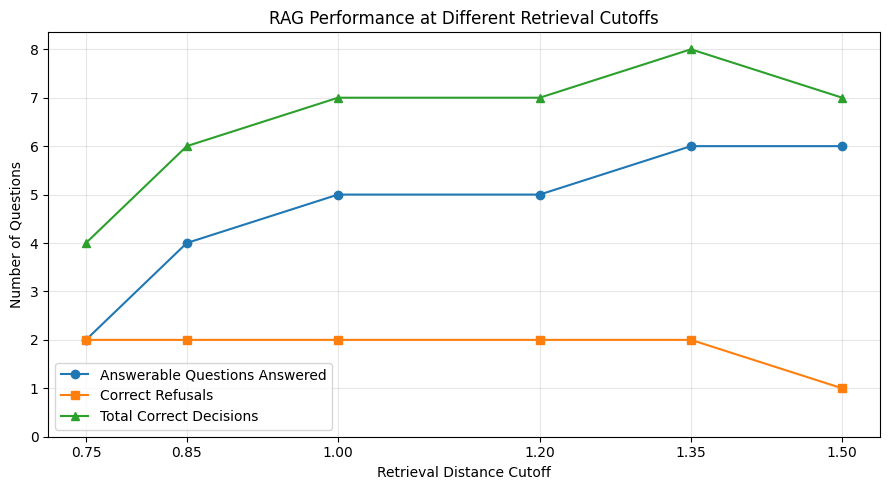

Chart saved to: rag_project/cutoff_experiment.png


In [37]:

import matplotlib.pyplot as plt
from pathlib import Path

# Create a chart comparing the retrieval cutoffs.
plt.figure(figsize=(9, 5))

plt.plot(
    df["Cutoff"],
    df["Answerable Answered"],
    marker="o",
    label="Answerable Questions Answered"
)

plt.plot(
    df["Cutoff"],
    df["Correct Refusals"],
    marker="s",
    label="Correct Refusals"
)

plt.plot(
    df["Cutoff"],
    df["Total Correct Decisions"],
    marker="^",
    label="Total Correct Decisions"
)

plt.title("RAG Performance at Different Retrieval Cutoffs")
plt.xlabel("Retrieval Distance Cutoff")
plt.ylabel("Number of Questions")
plt.xticks(df["Cutoff"])
plt.yticks(range(0, 9))
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Save the chart for the final report.
chart_path = Path("rag_project/cutoff_experiment.png")
plt.savefig(chart_path, dpi=300, bbox_inches="tight")

plt.show()

print("Chart saved to:", chart_path)


In [38]:

# Review all 8 RAG responses with the selected cutoff.

from pathlib import Path
import json

review_results = []

for i, item in enumerate(goldset, start=1):
    question = item["question"]
    response = rag_answer(question, cutoff=1.35)

    review_results.append({
        "question_number": i,
        "question": question,
        "expected_answerable": item["answerable"],
        "expected_evidence": item["evidence"],
        "response": response
    })

    print(f"\nQUESTION {i}")
    print("Question:", question)
    print("Expected evidence:", item["evidence"])
    print("RAG answer:", response)
    print("-" * 60)

# Save responses for the final report.
output_path = Path("rag_project/answer_review.json")

output_path.write_text(
    json.dumps(review_results, indent=2),
    encoding="utf-8"
)

print("\nAnswer review saved successfully!")



QUESTION 1
Question: Why should employees avoid reusing work passwords?
Expected evidence: ['attackers may try stolen']
RAG answer: [RAG] # Password Security

## Creating Strong Passwords
Employees should use long, unique passwords for every work account.
Source: password_security.md
------------------------------------------------------------

QUESTION 2
Question: What should employees do if they receive an unexpected financial request?
Expected evidence: ['unexpected financial requests']
RAG answer: [RAG] Employees should verify
unexpected financial requests through an independently
confirmed communication channel.
Source: phishing_awareness.md
------------------------------------------------------------

QUESTION 3
Question: What is an MFA fatigue attack?
Expected evidence: ['repeatedly sends']
RAG answer: [RAG] ## MFA Fatigue Attacks
An MFA fatigue attack occurs when an attacker repeatedly sends
authentication approval requests to a user's device, hoping the
user will eventually a

In [39]:

from pathlib import Path
import shutil

project = Path("rag_project")

# Create a ZIP containing your project files.
zip_path = shutil.make_archive(
    "/content/rag_project_backup",
    "zip",
    root_dir=project
)

print("Project backup created:", zip_path)
print("\nFiles included:")

for file in sorted(project.rglob("*")):
    if file.is_file():
        print("-", file.relative_to(project))


Project backup created: /content/rag_project_backup.zip

Files included:
- answer_review.json
- cutoff_experiment.png
- goldset.json
- my_kb/SOURCES.md
- my_kb/incident_reporting.md
- my_kb/multifactor_authentication.md
- my_kb/password_security.md
- my_kb/phishing_awareness.md
- my_kb/safe_browsing.md


In [40]:

from pathlib import Path

output = Path("rag_project/results.csv")

df.to_csv(output, index=False)

print("Results saved successfully!")
print("File:", output)
print("Experiment configurations:", len(df))


Results saved successfully!
File: rag_project/results.csv
Experiment configurations: 6


In [41]:

import shutil

zip_path = shutil.make_archive(
    "/content/rag_project_backup",
    "zip",
    root_dir="rag_project"
)

print("Updated backup created:", zip_path)


Updated backup created: /content/rag_project_backup.zip
